# make_moons训练MLP

## 1.导入必要的库

In [1]:
from sklearn.datasets import make_moons # make_moons数据集，返回值为X， y
from sklearn.model_selection import train_test_split # 数据集划分器
from sklearn.preprocessing import StandardScaler # 归一化工具
from torch.utils.data import DataLoader, TensorDataset
import torch
from torch import nn

## 2.加载数据集

In [2]:
X, y = make_moons(random_state=1, n_samples = 10000, noise = 0.1) 
# 随机种子方便复现，样本数，噪声（噪声越小月亮越清晰，足够小可能还会变成两条圆弧）

# 传入X，y；临时集的占比；随机种子；是否分层随机抽样
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 1,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size = 0.5,
    random_state=1,
    stratify=y_temp
)

# 保存一下方便画图
X_train_raw, y_train_raw = X_train, y_train
X_val_raw,   y_val_raw   = X_val,   y_val
X_test_raw,  y_test_raw  = X_test,  y_test

## 3.数据处理

In [3]:
scaler = StandardScaler()
# 归一化
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

# 转成张量
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

# 放到DataLoader中
train_ds = TensorDataset(X_train, y_train)
val_ds = TensorDataset(X_val, y_val)
test_ds = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)


## 4.模型构建

In [4]:
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

## 5.超参数等的设置

In [5]:
import torch.optim as optim
epochs = 20
lr = 1e-3 # learning rate
loss_fn = nn.CrossEntropyLoss()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = MyModel().to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)

## 6.定义train、test、val函数

In [6]:
def train(dataloader, model, loss_fn, optimizer):
    loss, acc, n = 0.0, 0.0, 0
    model.train()
    for batch, (x, y) in enumerate(dataloader):
        input, y = x.to(device), y.to(device)
        output = model(input)
        cur_loss = loss_fn(output, y)
        _, pred = torch.max(output, axis=1)
        cur_acc = torch.sum(y == pred) / output.shape[0]

        optimizer.zero_grad()
        cur_loss.backward()
        optimizer.step()

        loss += cur_loss.item()
        acc += cur_acc.item()
        n += 1
    return loss/n, acc/n

In [7]:
def test(dataloader, model, loss_fn):
    loss, acc, n = 0.0, 0.0, 0
    
    # 调整到评估模式
    model.eval()
    for batch, (x, y) in enumerate(dataloader):
        input, y = x.to(device), y.to(device)
        output = model(input)
        cur_loss = loss_fn(output, y)
        _, pred = torch.max(output, axis=1)
        cur_acc = torch.sum(y == pred) / output.shape[0]


        loss += cur_loss.item()
        acc += cur_acc.item()
        n += 1
    return loss/n, acc/n

In [8]:
# val跟test的差不多，只是调用位置不一样
def val(dataloader, model, loss_fn):
    loss, acc, n = 0.0, 0.0, 0
    
    # 调整到评估模式
    model.eval()
    with torch.no_grad():
        for param in model.parameters():
            param.requires_grad = False
            
    for batch, (x, y) in enumerate(dataloader):
        input, y = x.to(device), y.to(device)
        output = model(input)
        cur_loss = loss_fn(output, y)
        _, pred = torch.max(output, axis=1)
        cur_acc = torch.sum(y == pred) / output.shape[0]


        loss += cur_loss.item()
        acc += cur_acc.item()
        n += 1
    # 重新打开防止永久冻结
    for param in model.parameters():
        param.requires_grad = True
    return loss/n, acc/n

## 7.开始训练

In [9]:
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []} # 方便画图
for epoch in range(1, epochs+1):
    train_loss, train_acc = train(train_loader, model, loss_fn, optimizer)
    test_loss, test_acc = test(test_loader, model, loss_fn)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    print(f"---epoch{epoch}---\ntrain loss:{train_loss:.4f} | train_acc:{train_acc:.4f}\ntest_acc:{test_acc:.4f}")
_, val_acc = val(val_loader, model, loss_fn)
print(f"Final acc is {val_acc:.4f}")

---epoch1---
train loss:0.1079 | train_acc:0.9561
test_acc:0.9980
---epoch2---
train loss:0.0054 | train_acc:0.9980
test_acc:0.9971
---epoch3---
train loss:0.0049 | train_acc:0.9985
test_acc:0.9971
---epoch4---
train loss:0.0039 | train_acc:0.9990
test_acc:0.9951
---epoch5---
train loss:0.0036 | train_acc:0.9988
test_acc:0.9971
---epoch6---
train loss:0.0045 | train_acc:0.9981
test_acc:0.9980
---epoch7---
train loss:0.0029 | train_acc:0.9991
test_acc:0.9971
---epoch8---
train loss:0.0045 | train_acc:0.9985
test_acc:0.9980
---epoch9---
train loss:0.0033 | train_acc:0.9988
test_acc:0.9980
---epoch10---
train loss:0.0026 | train_acc:0.9994
test_acc:0.9971
---epoch11---
train loss:0.0039 | train_acc:0.9988
test_acc:0.9971
---epoch12---
train loss:0.0029 | train_acc:0.9989
test_acc:0.9980
---epoch13---
train loss:0.0025 | train_acc:0.9988
test_acc:0.9980
---epoch14---
train loss:0.0034 | train_acc:0.9988
test_acc:0.9971
---epoch15---
train loss:0.0023 | train_acc:0.9992
test_acc:0.9990
---e

## 8.各类画图函数定义、结果展示

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [11]:
def plot_original_data(X, y, title="原始数据"):
    """绘制原始数据散点图"""
    plt.figure(figsize=(6, 5))
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:red', s=8, alpha=0.6, label='class 0')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:blue', s=8, alpha=0.6, label='class 1')
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_data_splits(X_train, y_train, X_val, y_val, X_test, y_test):
    """绘制训练/验证/测试集的数据分布"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    datasets = [
        (X_train, y_train, "Train"),
        (X_val, y_val, "Val"),
        (X_test, y_test, "Test")
    ]
    for ax, (Xs, ys, name) in zip(axes, datasets):
        ax.scatter(Xs[ys == 0, 0], Xs[ys == 0, 1], c='tab:red', s=6, alpha=0.6, label='class 0')
        ax.scatter(Xs[ys == 1, 0], Xs[ys == 1, 1], c='tab:blue', s=6, alpha=0.6, label='class 1')
        ax.set_title(f"{name} (n={len(ys)})")
        ax.legend()
    plt.tight_layout()
    plt.show()


def plot_training_curves(history):
    """绘制训练和验证的 loss/accuracy 曲线
    history: dict, 包含 'train_loss', 'test_loss', 'train_acc', 'test_acc' 列表
    """
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(epochs, history['train_loss'], label='train loss', marker='o')
    axes[0].plot(epochs, history['test_loss'], label='test loss', marker='s')
    axes[0].set_xlabel('epoch')
    axes[0].set_ylabel('loss')
    axes[0].set_title('Loss 曲线')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history['train_acc'], label='train acc', marker='o')
    axes[1].plot(epochs, history['test_acc'], label='test acc', marker='s')
    axes[1].set_xlabel('epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].set_title('Accuracy 曲线')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_decision_boundary(model, X, y, scaler=None, device='cpu', title="Decision Boundary"):
    """绘制二维决策边界
    X, y: 原始尺度的 numpy 数组（未标准化）
    scaler: 训练好的 StandardScaler，用于将网格点标准化；若为 None 则直接输入模型
    """
    model.eval()
    # 生成网格
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # 标准化并转 tensor
    if scaler is not None:
        grid = scaler.transform(grid)
    grid_tensor = torch.tensor(grid, dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = model(grid_tensor)
        preds = logits.argmax(dim=1).cpu().numpy()
    Z = preds.reshape(xx.shape)

    # 画图
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:red', s=6, alpha=0.6, label='class 0')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:blue', s=6, alpha=0.6, label='class 1')
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(model, X_tensor, y_tensor, device='cpu'):
    """绘制混淆矩阵
    X_tensor, y_tensor: 标准化后的 tensor（与模型输入一致）
    """
    model.eval()
    with torch.no_grad():
        X_tensor = X_tensor.to(device)
        logits = model(X_tensor)
        preds = logits.argmax(dim=1).cpu().numpy()
    y_true = y_tensor.cpu().numpy() if isinstance(y_tensor, torch.Tensor) else y_tensor

    cm = confusion_matrix(y_true, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["class 0", "class 1"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()
    return cm

C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:10: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:10: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:10: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:10: UserWarning: Glyph 25454 (\N{CJK UNIFIED IDEOGRAPH-636E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\anaconda3\envs\CV\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\34854\anaconda3\envs\CV\lib\site-packages\IPython\

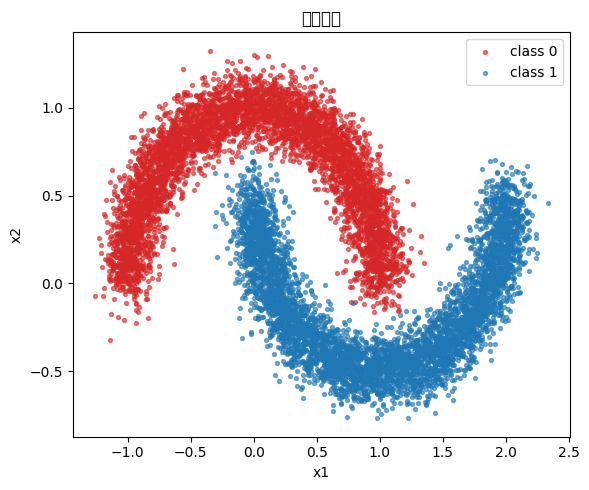

In [12]:
"""绘制原始数据散点图"""
plot_original_data(X=X, y=y)

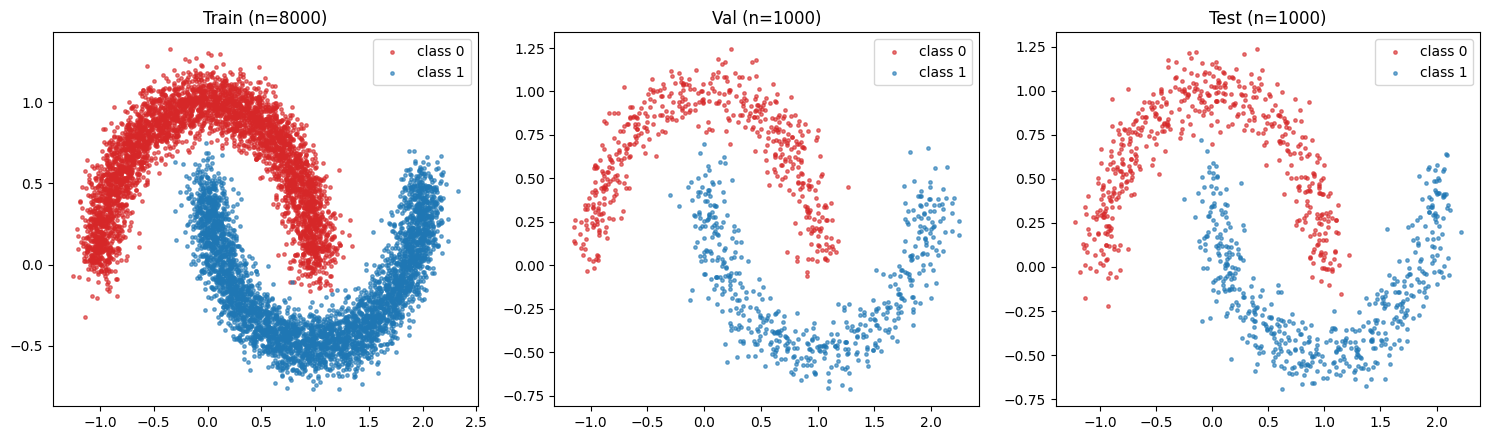

In [13]:
"""绘制训练/验证/测试集的数据分布"""
plot_data_splits(X_train_raw, y_train_raw, X_val_raw, y_val_raw, X_test_raw, y_test_raw)

C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:54: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\AppData\Local\Temp\ipykernel_27040\3838171510.py:54: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\34854\anaconda3\envs\CV\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\34854\anaconda3\envs\CV\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


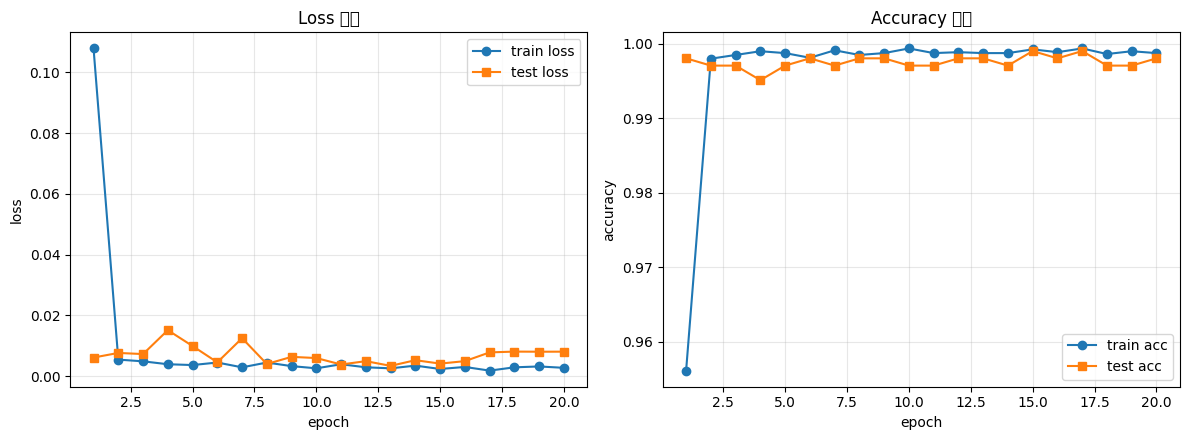

In [14]:
"""绘制训练和验证的 loss/accuracy 曲线"""
plot_training_curves(history)

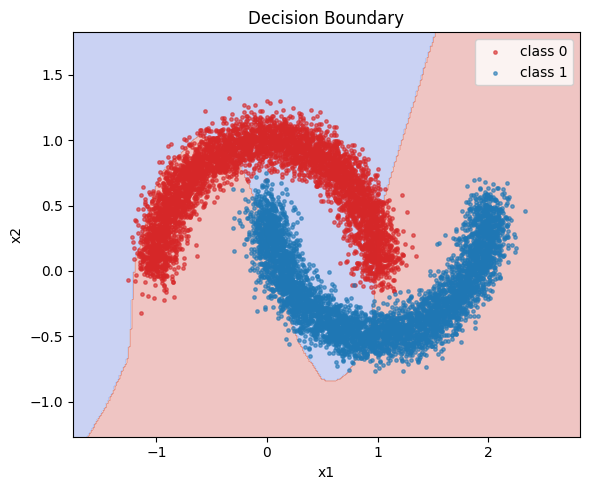

In [15]:
"""绘制二维决策边界"""
plot_decision_boundary(model, X, y, scaler=None, device='cuda', title="Decision Boundary")

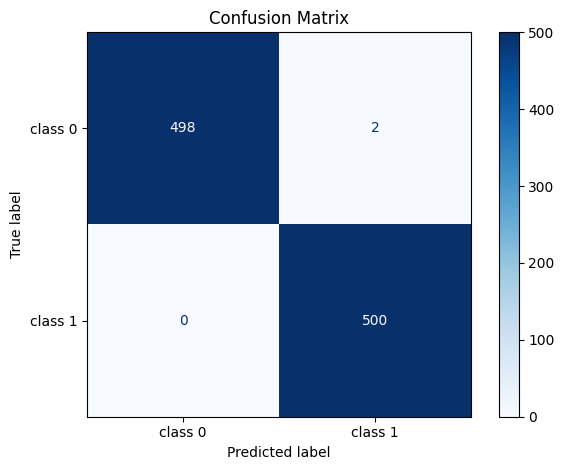

array([[498,   2],
       [  0, 500]])

In [16]:
"""绘制混淆矩阵"""
plot_confusion_matrix(model, X_test, y_test, device='cuda')